<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_2_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Başlangıç: Örnek Görselin Oluşturulması

Görevleri gerçekleştirebilmek için öncelikle tek kanallı (gri seviye - grayscale) örnek bir görsel oluşturalım veya indirelim. Bu örnekte NumPy kullanarak 512x512 boyutlarında yapay bir gri tonlamalı görsel üreteceğiz.

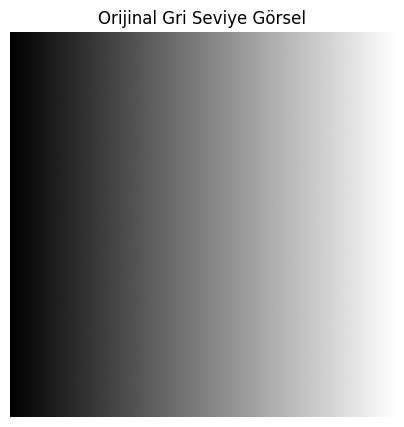

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time
import threading

# 512x512 boyutlarında gradyan geçişli bir gri seviye görsel oluşturalım
image = np.zeros((512, 512), dtype=np.uint8)
for i in range(512):
    image[:, i] = i // 2

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Orijinal Gri Seviye Görsel")
plt.axis('off')
plt.show()

### Task-1: 8-bit'ten 6-bit'e Parlaklık Nicemleme (Quantization)

**Konu Anlatımı:**
8-bit bir görselde her piksel $2^8 = 256$ farklı parlaklık değeri alabilir (0-255). 6-bit nicemlemede ise piksel değerleri $2^6 = 64$ farklı seviyeye (0-63) düşürülür.

Bunu gerçekleştirmek için piksel değerlerini önce $2^{8-6} = 2^2 = 4$'e böleriz (böylece değer aralığı 0-63 olur). Görseli tekrar 8-bit formatında gösterebilmek için ise bu değerleri yeniden 4 ile çarparak orijinal ölçeğe (0-252 aralığına) genişletiriz. Bu işlem veri miktarını azaltırken görsel kalitesinde hafif bloklaşmalara (nicemleme gürültüsü) yol açar.

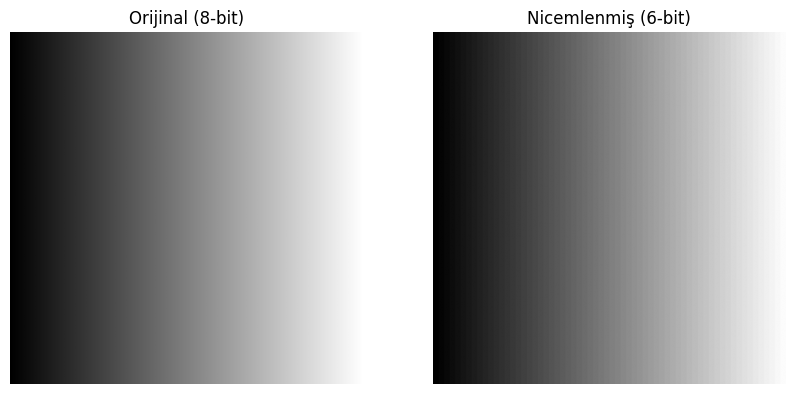

In [ ]:
# 8-bit'ten 6-bit'e nicemleme
# 2^2 = 4 seviye daraltma
quantized_6bit = (image // 4) * 4

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Orijinal (8-bit)")
axes[0].axis('off')

axes[1].imshow(quantized_6bit, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Nicemlenmiş (6-bit)")
axes[1].axis('off')

plt.show()

### Task-2 & Task-3: Çoklu İş Parçacığı (Multi-threading) ile Parlaklık Ayarlama ve Süre Karşılaştırması

**Konu Anlatımı:**
Görseli 4 eşit parçaya (yatay veya dikey şeritler halinde) bölüp her parçayı ayrı bir iş parçacığında (thread) işleyebiliriz. Her parçaya farklı bir parlaklık ofseti ekleyeceğiz.

Python'da `threading` kütüphanesini kullanarak 4 farklı thread tanımlayacağız. Ayrıca tek thread ile tüm görseli tek seferde işleyerek aradaki süre farkını ölçeceğiz.

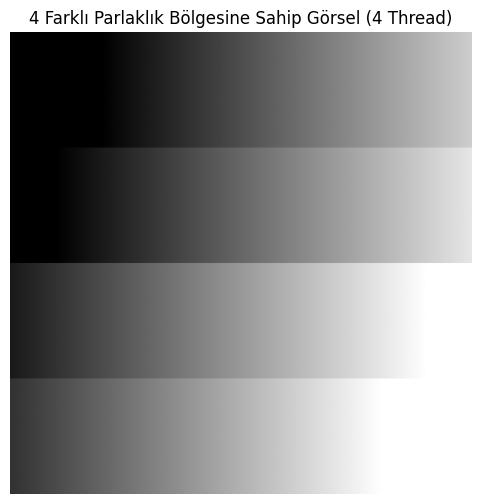

Tek Thread Süresi: 0.000398 saniye
Çoklu Thread (4 Thread) Süresi: 0.002709 saniye
Fark: 0.002310 saniye


In [ ]:
# Her parça için farklı parlaklık değişim miktarları
brightness_offsets = [-50, -25, 25, 50]

def adjust_brightness_chunk(img, start_row, end_row, offset, output_img):
    # Değerlerin 0-255 arasında kalmasını sağlamak için clip kullanıyoruz
    chunk = img[start_row:end_row, :].astype(np.int16) + offset
    output_img[start_row:end_row, :] = np.clip(chunk, 0, 255).astype(np.uint8)

# 1. ÇOKLU THREAD (4 Thread) UYGULAMASI
output_multithread = np.zeros_like(image)
height = image.shape[0]
chunk_size = height // 4
threads = []

start_time_multi = time.perf_counter()
for i in range(4):
    start_row = i * chunk_size
    end_row = (i + 1) * chunk_size
    t = threading.Thread(
        target=adjust_brightness_chunk,
        args=(image, start_row, end_row, brightness_offsets[i], output_multithread)
    )
    threads.append(t)
    t.start()

for t in threads:
    t.join()
end_time_multi = time.perf_counter()
multi_thread_duration = end_time_multi - start_time_multi

# 2. TEK THREAD (Single Thread) UYGULAMASI
output_singlethread = np.zeros_like(image)
start_time_single = time.perf_counter()
for i in range(4):
    start_row = i * chunk_size
    end_row = (i + 1) * chunk_size
    adjust_brightness_chunk(image, start_row, end_row, brightness_offsets[i], output_singlethread)
end_time_single = time.perf_counter()
single_thread_duration = end_time_single - start_time_single

# Sonuçları Görselleştirme
plt.figure(figsize=(6, 6))
plt.imshow(output_multithread, cmap='gray', vmin=0, vmax=255)
plt.title("4 Farklı Parlaklık Bölgesine Sahip Görsel (4 Thread)")
plt.axis('off')
plt.show()

print(f"Tek Thread Süresi: {single_thread_duration:.6f} saniye")
print(f"Çoklu Thread (4 Thread) Süresi: {multi_thread_duration:.6f} saniye")
print(f"Fark: {abs(single_thread_duration - multi_thread_duration):.6f} saniye")

### Task-4 & Task-5: Paralel Histogram Hesaplama ve Süre Karşılaştırması

**Konu Anlatımı:**
Histogram, bir görseldeki piksel değerlerinin dağılımını gösterir. Görseli 4 parçaya bölüp her parçanın lokal histogramını bağımsız thread'ler vasıtasıyla paralel olarak hesaplayacağız. Son aşamada ise elde edilen bu 4 lokal histogramı toplayarak ana histogramı elde edeceğiz.

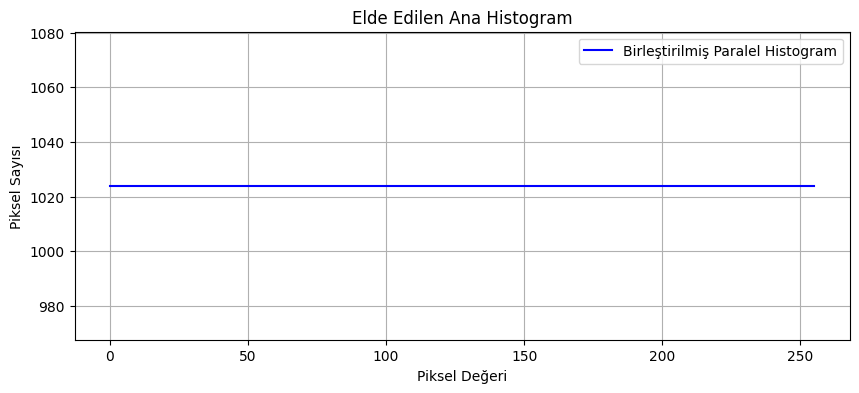

Tek Thread Histogram Süresi: 0.004383 saniye
Çoklu Thread (4 Thread) Histogram Süresi: 0.012280 saniye


In [ ]:
def calculate_local_histogram(img, start_row, end_row, hist_list, index):
    chunk = img[start_row:end_row, :]
    # 256 elemanlı histogram hesaplama
    hist, _ = np.histogram(chunk, bins=256, range=(0, 256))
    hist_list[index] = hist

# 1. ÇOKLU THREAD HİSTOGRAM HESAPLAMA
hist_list_multi = [None] * 4
threads_hist = []

start_time_hist_multi = time.perf_counter()
for i in range(4):
    start_row = i * chunk_size
    end_row = (i + 1) * chunk_size
    t = threading.Thread(
        target=calculate_local_histogram,
        args=(image, start_row, end_row, hist_list_multi, i)
    )
    threads_hist.append(t)
    t.start()

for t in threads_hist:
    t.join()

# Lokal histogramları birleştirme
final_hist_multi = np.sum(hist_list_multi, axis=0)
end_time_hist_multi = time.perf_counter()
multi_hist_duration = end_time_hist_multi - start_time_hist_multi

# 2. TEK THREAD HİSTOGRAM HESAPLAMA
start_time_hist_single = time.perf_counter()
final_hist_single, _ = np.histogram(image, bins=256, range=(0, 256))
end_time_hist_single = time.perf_counter()
single_hist_duration = end_time_hist_single - start_time_hist_single

# Sonuçları Çizdirme
plt.figure(figsize=(10, 4))
plt.plot(final_hist_multi, color='blue', label='Birleştirilmiş Paralel Histogram')
plt.title("Elde Edilen Ana Histogram")
plt.xlabel("Piksel Değeri")
plt.ylabel("Piksel Sayısı")
plt.legend()
plt.grid(True)
plt.show()

print(f"Tek Thread Histogram Süresi: {single_hist_duration:.6f} saniye")
print(f"Çoklu Thread (4 Thread) Histogram Süresi: {multi_hist_duration:.6f} saniye")

### Task-6: Piksel Çarpma ve Ekleme Karşılaştırması

**Konu Anlatımı:**
Piksel değerlerini bir katsayı ile çarpmak kontrastı ayarlar. Üzerine sabit bir değer eklemek ise parlaklığı artırır.
Burada iki durumu kıyaslayacağız:
1. Durum: Sadece kontrast değişimi ($f(x) = x \times 0.75$)
2. Durum: Kontrast ve parlaklık değişimi birlikte ($g(x) = x \times 0.75 + 20$)

Bu iki sonucu hem görsel hem de sayısal (ortalama parlaklık değerleri üzerinden) karşılaştıracağız.

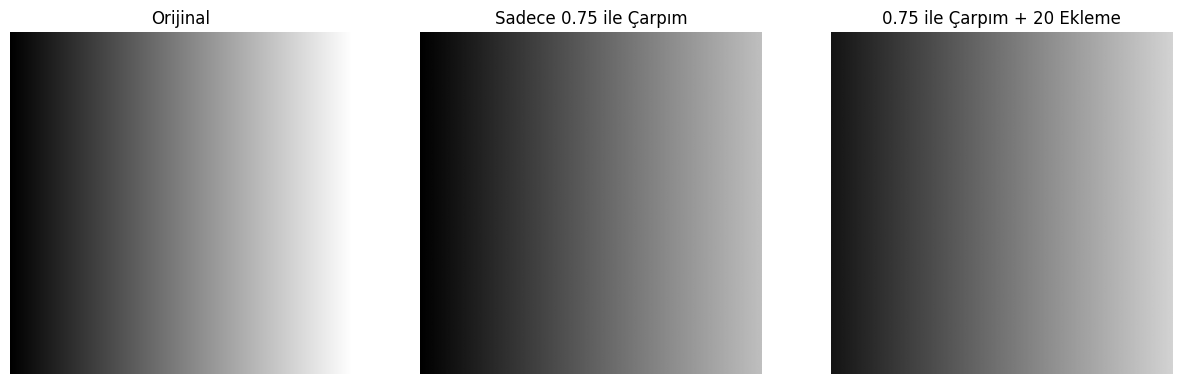

--- Sayısal Karşılaştırma (Ortalama Piksel Değerleri) ---
Orijinal Görsel Ortalaması: 127.50
Sadece 0.75 ile Çarpılan Görsel Ortalaması: 95.25 (Beklenen Azalma)
0.75 ile Çarpılıp 20 Eklenen Görsel Ortalaması: 115.25 (Parlaklık Telafisi)


In [ ]:
# Sadece 0.75 ile çarpılan durum
img_only_multiply = np.clip(image.astype(np.float32) * 0.75, 0, 255).astype(np.uint8)

# 0.75 ile çarpılıp 20 eklenen durum
img_multiply_and_add = np.clip((image.astype(np.float32) * 0.75) + 20, 0, 255).astype(np.uint8)

# Görsel Karşılaştırma
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Orijinal")
axes[0].axis('off')

axes[1].imshow(img_only_multiply, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Sadece 0.75 ile Çarpım")
axes[1].axis('off')

axes[2].imshow(img_multiply_and_add, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("0.75 ile Çarpım + 20 Ekleme")
axes[2].axis('off')

plt.show()

# Sayısal Karşılaştırma
mean_orig = np.mean(image)
mean_mult = np.mean(img_only_multiply)
mean_mult_add = np.mean(img_multiply_and_add)

print("--- Sayısal Karşılaştırma (Ortalama Piksel Değerleri) ---")
print(f"Orijinal Görsel Ortalaması: {mean_orig:.2f}")
print(f"Sadece 0.75 ile Çarpılan Görsel Ortalaması: {mean_mult:.2f} (Beklenen Azalma)")
print(f"0.75 ile Çarpılıp 20 Eklenen Görsel Ortalaması: {mean_mult_add:.2f} (Parlaklık Telafisi)")